In [2]:
import h5py
data = h5py.File("iGluSnFR_Ras.mat")
import numpy as np
import matplotlib.pyplot as plt


In [3]:
a1 = data['iGluSnFR_Ras']['animal_1']
print(list(a1.keys()))

['EMG', 'MUA', 'glutamate']


In [4]:
EMG = a1['EMG']
RSC = a1['glutamate']['RSC']

In [5]:
emg_amp = np.abs(EMG)
emg_score = np.mean(emg_amp, axis=0)
thresh = np.median(emg_score)

In [6]:
low_mask= emg_score< thresh
rsc_low = RSC[:,low_mask]
high_mask = emg_score >= thresh
rsc_high = RSC[:,high_mask]
print(rsc_low.shape, rsc_high.shape)

(201, 432) (201, 433)


In [7]:
rsc_low_mean = np.mean(rsc_low, axis=1)
rsc_high_mean= np.mean(rsc_high, axis=1)

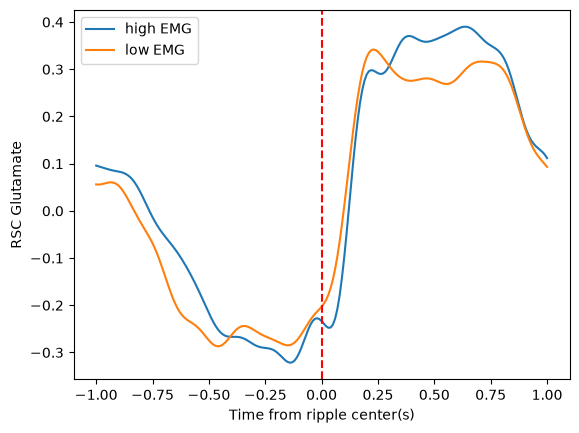

In [8]:
t_rsc = np.linspace(-1,1,201)
plt.plot(t_rsc,rsc_high_mean,label = "high EMG")
plt.plot(t_rsc,rsc_low_mean,label = "low EMG")
plt.axvline(0, color='r',linestyle='--')
plt.xlabel("Time from ripple center(s)")
plt.ylabel("RSC Glutamate")
plt.legend()
plt.show()

In [9]:
cortex_name = a1['glutamate'].keys()
cortex = a1['glutamate']
cortex_data = []
for key in cortex_name:
    region= cortex[key][:].mean(axis=1)
    cortex_data.append(region)
matrix = np.array(cortex_data)
print(matrix.shape)

(15, 201)


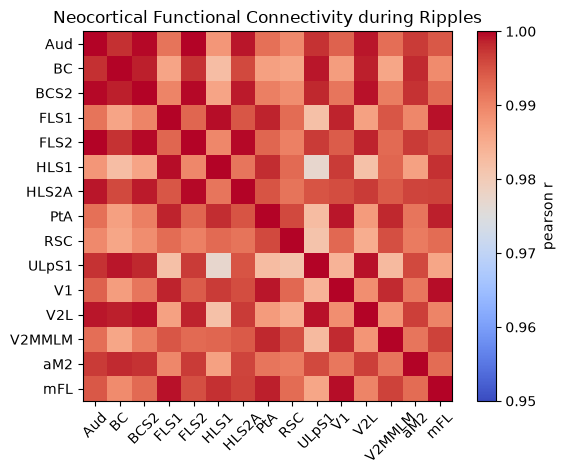

In [10]:
fc_matrix = np.corrcoef(matrix)
plt.imshow(fc_matrix,cmap='coolwarm',vmin=0.95,vmax=1)
plt.xticks(np.arange(15),cortex_name,rotation=45)
plt.yticks(np.arange(15),cortex_name)
plt.colorbar(label="pearson r")
plt.title("Neocortical Functional Connectivity during Ripples")
plt.show()